In [1]:
# 让 notebook 无论从哪个目录启动都能 import retailinsight
import sys
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
_root = next(p for p in _candidates if (p / "retailinsight" / "__init__.py").exists())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
print("项目根目录:", _root)


项目根目录: /Users/lizhipeng/个人成长/职业发展/求职面试/项目/RetailInsight


# 01 · EDA 数据探索
> 目标：摸清数据规模、质量与业务形态，并**回收计划 §4.2 预埋的关联锚点**。
> 纪律：所有指标调用 `retailinsight`，不重算。

In [2]:
import pandas as pd

from retailinsight.io.loader import read_items, read_parquet
from retailinsight.settings import INTERIM_DIR, ITEMS_DIR

pd.set_option("display.max_columns", 50)
members = read_parquet(INTERIM_DIR / "members.parquet")
txn = read_parquet(INTERIM_DIR / "transactions.parquet")
items = read_items(ITEMS_DIR)
products = read_parquet(INTERIM_DIR / "products.parquet")
stores = read_parquet(INTERIM_DIR / "stores.parquet")

for name, df in [("members", members), ("transactions", txn),
                 ("transaction_items", items), ("products", products), ("stores", stores)]:
    print(f"{name:20s} rows={len(df):>9,}  cols={df.shape[1]:>3}  缺失率={df.isna().mean().mean():.2%}")


members              rows=   36,000  cols=  7  缺失率=0.00%
transactions         rows=  313,571  cols= 10  缺失率=0.00%
transaction_items    rows=2,174,049  cols=  5  缺失率=0.00%
products             rows=    5,000  cols=  6  缺失率=0.00%
stores               rows=       15  cols=  5  缺失率=0.00%


## 1.1 时间覆盖与业务规模

In [3]:
print("时间范围:", txn["txn_ts"].min(), "~", txn["txn_ts"].max())
print("会员数:", members["member_id"].nunique())
print("门店数:", stores["store_id"].nunique(), "| SKU 数:", products["sku"].nunique())
print("品类数:", products["category"].nunique())

sales = txn[(~txn["is_logic_error"]) & (~txn["is_return"])]
print("\n有效 GMV: %.1f 万元" % (sales["net_amount"].sum() / 1e4))
print("会员订单占比: %.1f%%" % (100 * (sales["member_type"] == "会员").mean()))


时间范围: 2010-01-01 00:00:00 ~ 2022-07-31 23:51:00
会员数: 36000
门店数: 15 | SKU 数: 5000
品类数: 60

有效 GMV: 4453.4 万元
会员订单占比: 97.0%


## 1.2 清洗前后的质量状况（质量报告同源）

In [4]:
from retailinsight.etl.quality import missing_rates

dfs = {"members": members, "transactions": txn, "items": items}
rates = missing_rates(dfs)
print("清洗后仍存在缺失的字段：", rates if rates else "无（缺失已被转为哨兵值/标记列）")

print("\n逻辑冲突行:", int(txn["is_logic_error"].sum()))
print("退货行:", int(txn["is_return"].sum()))
print("非会员交易行:", int((txn["member_type"] != "会员").sum()))


清洗后仍存在缺失的字段： {'members.gender': 0.03938888888888889, 'transactions.member_id': 0.02983056468869889}

逻辑冲突行: 1511
退货行: 3115
非会员交易行: 9354


## 1.3 埋点回收验证：4 组强关联商品组合
> 生成器预埋的 4 组组合（计划 §4.2）必须在真实挖掘结果里被找回，
> 这是「数据里确实有可被发现的故事」的证据。

In [5]:
from retailinsight.io.schema import ANCHOR_COMBOS
from retailinsight.settings import MART_RULES

rules = read_parquet(MART_RULES)
print(f"共 {len(rules)} 条规则（lift>1.5）\n")
for a, b, _target in ANCHOR_COMBOS:
    hit = rules[(rules["antecedents"].astype(str).str.contains(a, regex=False))
                & (rules["consequents"].astype(str).str.contains(b, regex=False))]
    if len(hit):
        print(f"  ✅ {a} → {b}: lift={hit['lift'].max():.2f}  confidence={hit['confidence'].max():.2f}")
    else:
        print(f"  ❌ {a} → {b}: 未回收")


共 177 条规则（lift>1.5）

  ❌ 啤酒 → 纸尿裤: 未回收
  ✅ 火锅底料 → 牛羊肉: lift=5.02  confidence=0.59
  ✅ 面包糕点 → 乳制品: lift=2.29  confidence=0.59
  ✅ 洗发水 → 护发素: lift=8.30  confidence=0.63


## 1.4 季节性与时段形态

,gmv,orders,aov
m,,,
2021-08,1371927.500,9511,144.25
2021-09,1476036.000,10348,142.64
2021-10,1732806.875,12040,143.92
2021-11,2741662.250,18937,144.78
2021-12,3153903.250,21790,144.74
2022-01,3022413.750,20774,145.49
2022-02,3082794.000,21273,144.92
2022-03,1471804.125,10156,144.92
2022-04,1519480.625,10589,143.50


/Users/lizhipeng/个人成长/职业发展/求职面试/项目/RetailInsight/.venv/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/lizhipeng/个人成长/职业发展/求职面试/项目/RetailInsight/.venv/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/lizhipeng/个人成长/职业发展/求职面试/项目/RetailInsight/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/lizhipeng/个人成长/职业发展/求职面试/项目/RetailInsight/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


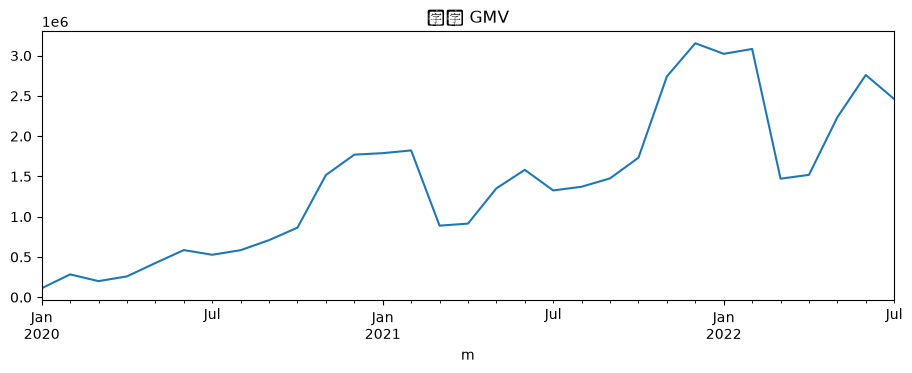

In [6]:
monthly = (sales.assign(m=sales["txn_ts"].dt.to_period("M"))
                 .groupby("m").agg(gmv=("net_amount", "sum"), orders=("txn_id", "nunique")))
monthly["aov"] = (monthly["gmv"] / monthly["orders"]).round(2)
ax = monthly["gmv"].plot(figsize=(11, 3.5), title="月度 GMV")
monthly.tail(12)
